# knob-senses — Random Forest para o ESP32

Treina a Random Forest que prevê **PCA** (potência CA do inversor, em kW) e **gera o
código C que roda no ESP32**, usando [emlearn](https://emlearn.readthedocs.io).

Este notebook é o caminho **sem Edge Impulse**. O motivo é técnico, não preferência:

- o Edge Impulse aceita upload em SavedModel, ONNX ou `.tflite` — e tudo vira TFLite/`EON` para o ESP32;
- **o TFLite não tem operação de árvore**. Convertendo a floresta para `.tflite`, a conversão
  "termina com sucesso" embrulhando a árvore numa *custom op* e o arquivo resultante nem
  aloca tensores (`Encountered unresolved custom op: ONNX_TREEENSEMBLEREGRESSOR`);
- então árvore não passa por lá. O emlearn resolve o mesmo problema por outro caminho:
  em vez de compilar um grafo, ele **escreve o C da floresta**, e o compilador do ESP32
  cuida do resto.

O irmão deste notebook é o `utils/treino_regressao.ipynb`, que faz o caminho do Keras +
Edge Impulse. Os dois leem os mesmos `data/processed/*.csv` e usam **ordens de feature
diferentes** — ver a seção 1.

## O contrato com o firmware

O modelo C recebe **grandezas brutas** (temperatura em °C, irradiância em W/m², dia do ano
em seno/cosseno) e faz a normalização z-score internamente, mais o *clip* na faixa física.
O firmware não precisa saber que existe normalização.

### De onde vem o número que a lib come

Quem alimenta a lib tem que entregar **grandeza física** — graus, W/m², seno e cosseno.
Duas coisas garantem que isso não se perca:

- `data/processed/*.csv` guardam as features **cruas**, sem normalização. A seção 2 tem um
  teste de faixa que quebra se alguém voltar a normalizar lá;
- o `utils/server.ipynb` manda as colunas do csv **verbatim**, sem tocar nelas.

O histórico importa, porque este contrato já foi violado uma vez. Quando os csv ainda vinham
em z-score, o servidor os mandava como estavam e o `pca_prever()` normalizava **de novo**:
tudo caía a ~7 desvios-padrão da média, todas as árvores caíam na mesma folha extrema, e a
previsão **colapsava num valor fixo** — `0.0505` em todas as linhas, com a entrada variando.
Nenhum teste offline pegava, porque todos alimentavam a lib com o bruto. A seção 9 agora
percorre o caminho inteiro, do csv ao kW.

## 1. Configuração

**A ordem das features é contrato.** As quatro primeiras são exatamente a ordem que o
`utils/server.ipynb` transmite pela rede (`AXES = temperatura_ambiente, ghi_cs, ghit,
jacques`), então o firmware entrega o que recebeu, sem reordenar. `sin1`/`cos1` vêm no fim.

> `utils/treino_regressao.ipynb` usa a ordem `temperatura_ambiente, ghi_cs, jacques, ghit,
> sin1, cos1` — com `jacques` e `ghit` trocados em relação a esta. São modelos separados,
> cada um com a sua ordem; **não troque as duas de lugar**.

In [1]:
from pathlib import Path
import json
import shutil
import subprocess
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import emlearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RAIZ = Path.cwd().parent          # os notebooks moram em utils/
PROCESSADO = RAIZ / "data" / "processed"

# A entrega e' uma biblioteca do PlatformIO, ao lado da lib/knob-senses/ do Edge
# Impulse. O notebook escreve nela: a proxima execucao sobrescreve.
LIB = RAIZ / "lib" / "knob-senses-rf"
SRC = LIB / "src"

# Residuo de build e o conferidor. Nao e' entrega.
SCRATCH = RAIZ / "data" / "modelo_rf"

SEMENTE = 42
ALVO = "PCA"

# A ordem importa: ver o aviso acima.
FEATURES = ["temperatura_ambiente", "ghi_cs", "ghit", "jacques", "sin1", "cos1", "PCA_lag1"]

# Escolhidos na varredura da secao 5.
N_ARVORES, MIN_FOLHA = 30, 50

# O inversor satura em ~2 kW e o dataset nao tem zero (o 0 e' sentinela de faltante,
# removido na analise). Prever fora desta faixa e' fisicamente impossivel.
PCA_MIN, PCA_MAX = 0.01, 2.02

np.random.seed(SEMENTE)

# O g++ do host confere a matematica compilando a propria lib; o xtensa mede o
# flash no alvo de verdade.
GXX = shutil.which("g++") or "g++"
XTENSA = Path.home() / ".platformio" / "packages" / "toolchain-xtensa-esp32s3" / "bin"
XTENSA_GXX = XTENSA / "xtensa-esp32s3-elf-g++.exe"
XTENSA_SIZE = XTENSA / "xtensa-esp32s3-elf-size.exe"

print("emlearn :", emlearn.__version__)
print("features:", ", ".join(FEATURES))
print("g++ host:", subprocess.run([GXX, "--version"], capture_output=True,
                                 text=True).stdout.splitlines()[0])
print("xtensa  :", "ok" if XTENSA_GXX.exists() else f"AUSENTE em {XTENSA}")
print("entrega :", LIB.relative_to(RAIZ))

emlearn : 0.23.2
features: temperatura_ambiente, ghi_cs, ghit, jacques, sin1, cos1, PCA_lag1
g++ host: g++.EXE (x86_64-posix-seh-rev0, Built by MinGW-Builds project) 16.1.0
xtensa  : ok
entrega : lib\knob-senses-rf


## 2. Os dados e as constantes de normalização

`data/processed/*.csv` guardam as features em **grandeza física**: graus, W/m², seno e
cosseno. A normalização z-score não acontece mais no notebook de análise — ela vive
**dentro do C** que roda no MCU.

Mas ela também precisa acontecer aqui, no treino: sem isso a floresta aprenderia sobre
graus e W/m², e o firmware alimentaria a árvore com z-scores. As constantes saem do split
de **treino** e são exatamente as que vão compiladas para o firmware — o mesmo número
servindo as duas pontas, gravado em `lib/knob-senses-rf/normalizacao.json`.

Isso não é duplicação: é a mesma conta, feita duas vezes, a partir do mesmo número.

In [2]:
treino = pd.read_csv(PROCESSADO / "train.csv", parse_dates=["datetime"])
valid = pd.read_csv(PROCESSADO / "validation.csv", parse_dates=["datetime"])
teste = pd.read_csv(PROCESSADO / "test.csv", parse_dates=["datetime"])

# Sanidade: o csv precisa estar em GRANDEZA FISICA. Se alguem voltar a normalizar no
# dataset_analisys.ipynb, estes limites quebram AQUI - e nao em campo, com o firmware
# normalizando duas vezes e a previsao colapsando num valor fixo. Foi o bug real, e
# custou uma sessao inteira de depuracao.
LIMITES = {
    "temperatura_ambiente": (-20.0, 60.0),
    "ghi_cs": (0.0, 1500.0),
    "ghit": (0.0, 1500.0),
    "jacques": (-20.0, 90.0),
    "sin1": (-1.0, 1.0),
    "cos1": (-1.0, 1.0),
}
for nome, d in (("train", treino), ("validation", valid), ("test", teste)):
    for c, (baixo, alto) in LIMITES.items():
        menor, maior = float(d[c].min()), float(d[c].max())
        assert baixo <= menor and maior <= alto, (
            f"{nome}.csv: {c} fora de [{baixo}, {alto}] (min {menor:.2f}, max {maior:.2f})"
            " - o csv nao esta em grandeza fisica")

print("OK: os tres csv estao em grandeza fisica (brutos)")
print()
print(f"{'feature':22} {'min':>9} {'max':>9} {'media treino':>14} {'desvio treino':>14}")
for c in FEATURES:
    print(f"{c:22} {treino[c].min():9.2f} {treino[c].max():9.2f} "
          f"{treino[c].mean():14.4f} {treino[c].std(ddof=0):14.4f}")

OK: os tres csv estao em grandeza fisica (brutos)

feature                      min       max   media treino  desvio treino
temperatura_ambiente       15.64     48.00        26.8773         4.0893
ghi_cs                     79.81   1061.47       625.1129       301.5938
ghit                        1.83   1289.63       470.1694       288.0758
jacques                    17.69     67.36        39.0495        11.1179
sin1                       -1.00      1.00        -0.0067         0.7070
cos1                       -1.00      1.00         0.0218         0.7069
PCA_lag1                    0.00      1.97         0.8764         0.5122


In [3]:
# Media e desvio SO do split de treino. Se validacao ou teste entrassem na conta,
# haveria vazamento do futuro para dentro do treino.
MEDIA = treino[FEATURES].mean()
DESVIO = treino[FEATURES].std(ddof=0)


def z_score(d):
    """Features em z-score, pelas constantes do treino.

    E' exatamente a conta que o pca_prever() faz dentro do MCU. Se as duas
    divergirem, o modelo do sklearn e o firmware deixam de concordar - e quem
    percebe e' o teste do caminho da rede, na secao 9.
    """
    return ((d[FEATURES] - MEDIA) / DESVIO).to_numpy(np.float32)


print("constantes de normalizacao (calculadas so no treino):")
print(f"  {'feature':22} {'media':>14} {'desvio':>14}")
for c in FEATURES:
    print(f"  {c:22} {MEDIA[c]:14.6f} {DESVIO[c]:14.6f}")

X_tre, y_tre = z_score(treino), treino[ALVO].to_numpy(np.float32)
X_val, y_val = z_score(valid), valid[ALVO].to_numpy(np.float32)
X_tes, y_tes = z_score(teste), teste[ALVO].to_numpy(np.float32)

# O C recebe BRUTO - e' o bruto do teste que vai para o conferidor, na ordem do csv.
BRUTO_TES = teste[FEATURES].to_numpy(np.float32)

print()
for nome, d in (("treino", treino), ("validacao", valid), ("teste", teste)):
    print(f"  {nome:10} {len(d):6} linhas | PCA {d[ALVO].min():.2f}..{d[ALVO].max():.2f} kW "
          f"| media {d[ALVO].mean():.3f}")

constantes de normalizacao (calculadas so no treino):
  feature                         media         desvio
  temperatura_ambiente        26.877282       4.089252
  ghi_cs                     625.112919     301.593771
  ghit                       470.169351     288.075849
  jacques                     39.049489      11.117925
  sin1                        -0.006697       0.706990
  cos1                         0.021813       0.706855
  PCA_lag1                     0.876404       0.512177

  treino       8285 linhas | PCA 0.00..1.97 kW | media 0.876
  validacao    4156 linhas | PCA 0.00..1.95 kW | media 0.876
  teste        3921 linhas | PCA 0.00..1.92 kW | media 0.877


## 3. Métricas

Três números, todos em kW (R² é adimensional):

- **MAE** — o erro típico. É a métrica de cabeça: compare com a potência do inversor
  (~2 kW) para ter noção de escala.
- **RMSE** — igual ao MAE, mas pune erro grande com mais força.
- **R²** — fração da variância explicada.

O julgamento é **no split de teste**, que é futuro de verdade. A validação não é usada
aqui — o RF não tem o que ajustar nela.

In [4]:
def avalia(nome, y, pred):
    """MAE/RMSE em kW e R2 adimensional. Reporta tambem com clip na faixa fisica."""
    pred_clip = np.clip(pred, PCA_MIN, PCA_MAX)
    linha = {
        "modelo": nome,
        "MAE (kW)": mean_absolute_error(y, pred),
        "RMSE (kW)": float(np.sqrt(mean_squared_error(y, pred))),
        "R2": r2_score(y, pred),
        "MAE com clip (kW)": mean_absolute_error(y, pred_clip),
        "vies (kW)": float((pred - y).mean()),
    }
    print(f"{nome:20} MAE {linha['MAE (kW)']:.4f} kW | RMSE {linha['RMSE (kW)']:.4f} kW "
          f"| R2 {linha['R2']:.4f} | vies {linha['vies (kW)']:+.4f} kW")
    return linha


resultados = []

## 4. Piso: a média do treino

O modelo mais burro possível que ainda acerta a média. Se a floresta não bater isto com
folga, ela não aprendeu nada.

In [5]:
from sklearn.dummy import DummyRegressor

media = DummyRegressor(strategy="mean").fit(X_tre, y_tre)
resultados.append(avalia("media do treino", y_tes, media.predict(X_tes).ravel()))

media do treino      MAE 0.4444 kW | RMSE 0.5136 kW | R2 -0.0000 | vies -0.0008 kW


## 5. Varredura: tamanho × acurácia

A floresta tem dois botões que controlam tamanho: quantas árvores e quantas amostras
mínimas por folha. Folha maior = árvore menor e mais suave.

O `n_estimators=300, min_samples_leaf=2` que é o default do sklearn **não é um bom ponto
neste dado**: gasta 25 MB de nós. A varredura abaixo existe para escolher com número na
mão.

A coluna `KB (est.)` é uma estimativa grosseira do payload (12 bytes por nó + 4 por
folha). Ela serve para **comparar** configurações, não para prometer flash: o número real
sai da compilação, na seção 8, e é bem menor porque o compilador enxuga as comparações.

In [6]:
print(f"{'config':>18} {'nos':>8} {'prof':>5} {'KB (est.)':>10} {'MAE':>8} {'R2':>8} {'s':>5}")
print("-" * 72)

varredura = []
for n_arv, folha in ((300, 2), (100, 2), (50, 5), (50, 20), (30, 50),
                     (20, 100), (12, 200), (6, 400)):
    t0 = time.perf_counter()
    m = RandomForestRegressor(n_estimators=n_arv, min_samples_leaf=folha,
                              n_jobs=-1, random_state=SEMENTE).fit(X_tre, y_tre)
    seg = time.perf_counter() - t0

    p = m.predict(X_tes)
    nos = sum(e.tree_.node_count for e in m.estimators_)
    folhas = sum(int((e.tree_.children_left == -1).sum()) for e in m.estimators_)
    kb = (nos * 12 + folhas * 4) / 1024
    prof = max(e.tree_.max_depth for e in m.estimators_)

    varredura.append({"arvores": n_arv, "folha": folha, "nos": nos, "kb": int(kb),
                      "mae": mean_absolute_error(y_tes, p), "r2": r2_score(y_tes, p)})
    print(f"{f'{n_arv}arv folha={folha}':>18} {nos:8} {prof:5} {kb:10.1f} "
          f"{varredura[-1]['mae']:8.4f} {varredura[-1]['r2']:8.4f} {seg:5.1f}")

melhor = min(varredura, key=lambda r: r["mae"])
print(f"\nmelhor MAE: {melhor['arvores']} arvores, folha={melhor['folha']} "
      f"({melhor['mae']:.4f}) com {melhor['kb']} KB estimados")

            config      nos  prof  KB (est.)      MAE       R2     s
------------------------------------------------------------------------
    300arv folha=2  1367162    31    18692.3   0.0974   0.9136   3.5
    100arv folha=2   455658    31     6229.9   0.0976   0.9134   1.2
     50arv folha=5    84110    23     1150.0   0.0974   0.9136   0.6
    50arv folha=20    20052    14      274.2   0.0987   0.9124   0.5
    30arv folha=50     4688     9       64.2   0.1016   0.9094   0.5
   20arv folha=100     1544     7       21.1   0.1039   0.9068   0.3
   12arv folha=200      456     5        6.3   0.1085   0.9016   0.4
    6arv folha=400       94     4        1.3   0.1160   0.8926   0.2

melhor MAE: 50 arvores, folha=5 (0.0974) com 1150 KB estimados


## 6. A floresta final

O ponto escolhido é `30 árvores, min_samples_leaf=50`. A varredura acima é a
justificativa: é onde a curva dobra. A partir daí, comprar acurácia custa flash em
proporção bem pior.

Como a floresta não tem estado a ajustar na validação, ela treina com **treino + validação**
juntos? Não — este notebook mantém `treino` apenas, para que o teste continue sendo um
número honesto e comparável com o do outro notebook.

In [7]:
rf = RandomForestRegressor(n_estimators=N_ARVORES, min_samples_leaf=MIN_FOLHA,
                           n_jobs=-1, random_state=SEMENTE)

t0 = time.perf_counter()
rf.fit(X_tre, y_tre)
print(f"treino: {time.perf_counter() - t0:.1f} s")

pred_rf = rf.predict(X_tes)
resultados.append(avalia("random forest", y_tes, pred_rf))

nos = sum(e.tree_.node_count for e in rf.estimators_)
print(f"\n{nos} nos em {rf.n_estimators} arvores "
      f"({nos // rf.n_estimators} por arvore, profundidade maxima "
      f"{max(e.tree_.max_depth for e in rf.estimators_)})")

treino: 0.5 s
random forest        MAE 0.1016 kW | RMSE 0.1546 kW | R2 0.9094 | vies +0.0578 kW

4688 nos em 30 arvores (156 por arvore, profundidade maxima 9)


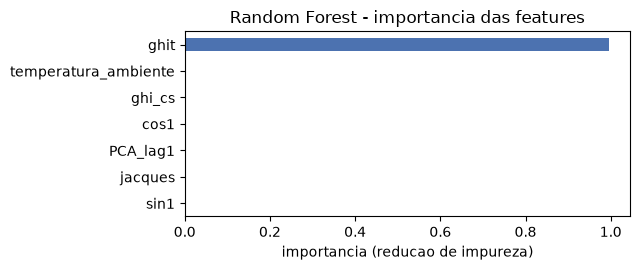

sin1                    0.0000
jacques                 0.0001
PCA_lag1                0.0003
cos1                    0.0010
ghi_cs                  0.0015
temperatura_ambiente    0.0015
ghit                    0.9955


In [8]:
importancia = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

ax = importancia.plot.barh(figsize=(6.5, 2.8), color="#4c72b0")
ax.set_xlabel("importancia (reducao de impureza)")
ax.set_title("Random Forest - importancia das features")
plt.tight_layout()
plt.show()

print(importancia.round(4).to_string())

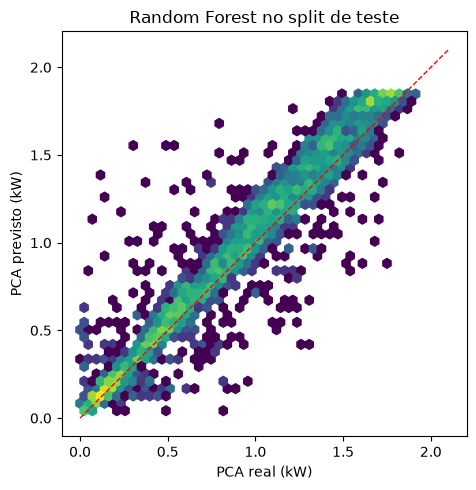

In [9]:
fig, eixo = plt.subplots(figsize=(6.5, 5))
eixo.hexbin(y_tes, pred_rf, gridsize=45, bins="log", cmap="viridis", extent=(0, 2.1, 0, 2.1))
eixo.plot([0, 2.1], [0, 2.1], "r--", lw=1)
eixo.set_xlabel("PCA real (kW)")
eixo.set_ylabel("PCA previsto (kW)")
eixo.set_title("Random Forest no split de teste")
eixo.set_aspect("equal")
plt.tight_layout()
plt.show()

## 7. Geração do código C

O `emlearn` escreve o C da floresta. Duas estratégias, com tamanho **medido no ESP32-S3**
(seção 9 para o método de medição):

| método | o que gera | flash | RAM | depende de |
|---|---|---|---|---|
| **`inline`** | um `if/else` por nó, direto no código | **93 KB** | 0 | nada além de `stdint.h` |
| `loadable` | arrays de nós percorridos por um interpretador | 39 KB | 28 B | `eml_trees.h` e `eml_common.h` |

O `loadable` economiza 54 KB, e a tentação é grande. A escolha aqui é **`inline`** mesmo
assim, por dois motivos:

1. **A quantização do `loadable` não está verificada.** Ele só aceita features `int16_t`, e
   os limiares de corte da árvore viram inteiros também. Numa floresta treinada em z-scores
   quebrados (`features[2] < -0.043423`), isso exige escolher uma escala e provar que
   nenhum limiar se desloca. Este notebook não faz essa prova — e um limiar deslocado não
   dá erro, dá previsão pior em silêncio.
2. **54 KB não pesam aqui.** O ESP32-S3 tem 16 MB de flash e o modelo atual do Edge Impulse
   ocupa ~112 KB. A troca não é entre caber e não caber.

Se um dia o flash apertar, é trocar `method='inline'` por `method='loadable'` e adicionar a
quantização — mas aí a verificação da seção 9 precisa rodar de novo, com a escala no lugar.

## 8. A biblioteca do PlatformIO

O modelo é entregue como uma **biblioteca do PlatformIO em `lib/knob-senses-rf/`**, na
mesma forma da `lib/knob-senses/` que veio do Edge Impulse:

```
lib/knob-senses-rf/
  library.json        manifesto do PlatformIO (nome, versao, frameworks)
  normalizacao.json   as constantes de z-score, para o Python ler
  README.md           o contrato e o custo, para quem for usar
  src/
    knob_senses_rf.h    API publica e os numeros de procedencia
    knob_senses_rf.cpp  implementacao: z-score, floresta, clip
    modelo_pca.h        as arvores, geradas pelo emlearn (nao editar)
```

O `normalizacao.json` grava as constantes que estão **compiladas dentro do C**. O firmware
não lê esse arquivo — ele existe para quem for conferir ou reproduzir a normalização fora
do C (o próprio notebook, um teste do lado do servidor), de modo que as constantes nunca
precisem ser transcritas à mão. Constante transcrita envelhece sozinha, e a que envelhece
errado não avisa.

O `platformio.ini` já tem `lib_ldf_mode = deep+`, então a lib é encontrada sem nenhuma
mudança de configuração — basta incluir o header.

**A API é uma função:**

```c
float pca_prever(const float bruto[KNOB_RF_N_FEATURES]);
```

Ela recebe as 6 grandezas **brutas**, normaliza, roda a floresta e devolve kW já ceifado na
faixa física. O firmware não precisa saber que existe normalização.

> Este notebook **escreve dentro de `lib/`**, que é diretório de código versionado. A
> próxima execução sobrescreve `src/`, `README.md` e `library.json` — não edite à mão.

### O que muda em relação à biblioteca do Edge Impulse

A `lib/knob-senses/` exporta `run_classifier(signal_t*, ei_impulse_result_t*, bool)`, com
`result.classification[0].value` e os tempos em `result.timing`. Esta lib **não** imita essa
API, de propósito:

- **não há `signal_t` nem janela.** A floresta decide com uma amostra; a janela de 12
  amostras que o `main.cpp` mantém existe para o modelo do Edge Impulse, que é uma rede.
  Aqui ela é desnecessária — e manter a filtragem por janela seria herança, não requisito.
- **não há `timing.dsp` nem `timing.classification`.** Não existem estágios separados:
  é uma chamada de função. Inventar esses campos seria fingir uma arquitetura que não está
  lá, e o `printResult()` do `main.cpp` mostraria número falso.

Ou seja: quem for trocar o modelo no firmware precisa mexer no `main.cpp` — a troca não é
só de `#include`. A seção 10 diz o que muda.

In [10]:
def preenche(modelo, **valores):
    """Substitui @@TOKEN@@ pelo valor.

    Os templates abaixo sao C, cheios de chave. Escrever isso como f-string significa
    escapar cada `{` e `}` como `{{` e `}}`, e basta um passar batido para o arquivo sair
    errado sem ninguem notar. Com marcador explicito nao ha o que escapar.
    """
    for chave, valor in valores.items():
        modelo = modelo.replace(f"@@{chave}@@", str(valor))
    return modelo


MEDIA_C = ",\n".join(f"    {MEDIA[c]:.6f}f" for c in FEATURES)
DESVIO_C = ",\n".join(f"    {DESVIO[c]:.6f}f" for c in FEATURES)
ORDEM_C = "\n".join(f" *   bruto[{i}] = {c}" for i, c in enumerate(FEATURES))
ORDEM_LISTA = ", ".join(FEATURES)
MAE = f"{resultados[-1]['MAE (kW)']:.4f}"
R2 = f"{resultados[-1]['R2']:.4f}"
VALORES = dict(N_FEATURES=len(FEATURES), N_ARVORES=N_ARVORES, MIN_FOLHA=MIN_FOLHA,
               NOS=nos, MAE=MAE, R2=R2, ORDEM_C=ORDEM_C, ORDEM_LISTA=ORDEM_LISTA,
               MEDIA_C=MEDIA_C, DESVIO_C=DESVIO_C, PCA_MIN=PCA_MIN, PCA_MAX=PCA_MAX)

print("marcadores que os templates usam:")
for chave in sorted(VALORES):
    print(f"  @@{chave}@@")

marcadores que os templates usam:
  @@DESVIO_C@@
  @@MAE@@
  @@MEDIA_C@@
  @@MIN_FOLHA@@
  @@NOS@@
  @@N_ARVORES@@
  @@N_FEATURES@@
  @@ORDEM_C@@
  @@ORDEM_LISTA@@
  @@PCA_MAX@@
  @@PCA_MIN@@
  @@R2@@


In [11]:
SRC.mkdir(parents=True, exist_ok=True)
SCRATCH.mkdir(parents=True, exist_ok=True)

cmodelo = emlearn.convert(rf, method="inline", dtype="float")
codigo = cmodelo.save(file=str(SRC / "modelo_pca.h"), name="modelo_pca")

print(f"{SRC / 'modelo_pca.h'}")
print(f"  {len(codigo):,} bytes de codigo C")
print(f"  funcao: float modelo_pca_predict(const float *features, int32_t features_length)")
print(f"\nprimeiras linhas:")
for linha in codigo.splitlines()[:8]:
    print("   ", linha)

c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\lib\knob-senses-rf\src\modelo_pca.h
  471,743 bytes de codigo C
  funcao: float modelo_pca_predict(const float *features, int32_t features_length)

primeiras linhas:
    
    
    
        // !!! This file is generated using emlearn !!!
    
        #include <stdint.h>
        
    


In [12]:
CABECALHO = '''/*
 * knob-senses - Random Forest de regressao de PCA (potencia CA do inversor, kW).
 *
 * GERADO POR utils/treino_random_forest.ipynb. NAO EDITE A MAO: a proxima execucao
 * do notebook sobrescreve este arquivo.
 *
 * Como usar:
 *
 *     #include <knob_senses_rf.h>
 *
 *     const float bruto[KNOB_RF_N_FEATURES] = { 26.1f, 480.0f, 310.5f, 38.7f,
 *                                               sin1, cos1 };
 *     const float kw = pca_prever(bruto);
 *
 * ORDEM DAS GRANDEZAS BRUTAS:
@@ORDEM_C@@
 *
 * O modelo foi treinado em z-scores e a normalizacao vive DENTRO desta lib (ver
 * knob_senses_rf.cpp): passe a grandeza fisica como ela veio do sensor. Nao normalize
 * antes de chamar pca_prever() - se o dado chegar em z-score, a conta acontece duas
 * vezes, tudo cai a ~7 desvios-padrao da media, e a previsao COLAPSA num valor fixo.
 *
 * Custo no ESP32-S3: ~93 KB de flash, 0 de RAM. A floresta e' emitida como codigo
 * (emlearn method='inline'), nao como tabela - por isso nao ocupa RAM.
 */
#ifndef KNOB_SENSES_RF_H
#define KNOB_SENSES_RF_H

#include <stddef.h>

/* --------------------------------------------------------------- contrato */

#define KNOB_RF_N_FEATURES @@N_FEATURES@@

/* Ordem esperada em bruto[]. As 4 primeiras sao exatamente a ordem que
 * utils/server.ipynb transmite pela rede, entao o firmware entrega o que
 * recebeu sem reordenar. */
#define KNOB_RF_ORDEM "@@ORDEM_LISTA@@"

/* Faixa fisica do alvo: o inversor satura em ~2 kW e o dataset nao tem zero (o
 * 0 era sentinela de faltante, removido na analise). A saida ja vem ceifada. */
#define KNOB_RF_PCA_MIN @@PCA_MIN@@f
#define KNOB_RF_PCA_MAX @@PCA_MAX@@f

/* ------------------------------------------------------------ procedencia */

#define KNOB_RF_N_ARVORES    @@N_ARVORES@@
#define KNOB_RF_FOLHA_MIN    @@MIN_FOLHA@@
#define KNOB_RF_N_NOS        @@NOS@@
#define KNOB_RF_MAE_TESTE    @@MAE@@f   /* kW, no split de teste (futuro) */
#define KNOB_RF_R2_TESTE     @@R2@@f

#ifdef __cplusplus
extern "C" {
#endif

/* bruto -> z-score -> floresta -> clip. Devolve a potencia CA em kW. */
float pca_prever(const float bruto[KNOB_RF_N_FEATURES]);

#ifdef __cplusplus
}
#endif

#endif /* KNOB_SENSES_RF_H */
'''

IMPLEMENTACAO = '''#include "knob_senses_rf.h"

/* As arvores, geradas pelo emlearn. Este header tem arrays static e so depende de
 * <stdint.h>; inclua-o em UM unico .cpp, senao a tabela entra duplicada no binario
 * (sem erro de link, mas com flash desperdicado). */
#include "modelo_pca.h"

/* Media e desvio, ajustados SO no split de treino (nunca na validacao nem no
 * teste). Recalculados do bruto a cada execucao de utils/treino_random_forest.ipynb
 * e conferidos contra data/processed/*.csv - ver a secao 2 do notebook. */
static const float PCA_MEDIA[KNOB_RF_N_FEATURES] = {
@@MEDIA_C@@
};

static const float PCA_DESVIO[KNOB_RF_N_FEATURES] = {
@@DESVIO_C@@
};

float pca_prever(const float bruto[KNOB_RF_N_FEATURES])
{
    float z[KNOB_RF_N_FEATURES];
    for (size_t i = 0; i < KNOB_RF_N_FEATURES; i++) {
        z[i] = (bruto[i] - PCA_MEDIA[i]) / PCA_DESVIO[i];
    }

    float p = modelo_pca_predict(z, KNOB_RF_N_FEATURES);

    /* A floresta extrapola fora do que viu; a faixa fisica nao. */
    if (p < KNOB_RF_PCA_MIN) p = KNOB_RF_PCA_MIN;
    if (p > KNOB_RF_PCA_MAX) p = KNOB_RF_PCA_MAX;
    return p;
}
'''

LEIAME = '''# knob-senses-rf

Random Forest de regressao de **PCA** (potencia CA do inversor, em kW) do projeto
knob-senses, gerada com [emlearn](https://emlearn.readthedocs.io).

Gerada por `utils/treino_random_forest.ipynb`. Nao edite os arquivos de `src/` a mao: a
proxima execucao do notebook os sobrescreve.

## Uso

```cpp
#include <knob_senses_rf.h>

const float bruto[KNOB_RF_N_FEATURES] = {
    26.1f, 480.0f, 310.5f, 38.7f,   // temperatura, ghi_cs, ghit, jacques
    sin1, cos1,                      // do ciclo anual, calculados no device
};

const float kw = pca_prever(bruto);
```

## Contrato

A ordem de `bruto` e' **@@ORDEM_LISTA@@**.

As 4 primeiras sao exatamente a ordem que o `utils/server.ipynb` transmite pela rede, entao o
firmware entrega o que recebeu sem reordenar. `sin1`/`cos1` sao o 1o harmonico do ciclo anual
e tambem chegam pela rede, ja calculados.

**Passe valores BRUTOS.** A normalizacao z-score acontece dentro da lib, com as constantes
de `normalizacao.json` (que fica ao lado deste header).

> **O que da' errado se nao for bruto.** Se o dado chegar **ja em z-score** e a lib normalizar
> de novo, a conta acontece duas vezes: tudo cai a ~7 desvios-padrao da media, todas as
> arvores caem na mesma folha extrema, e a previsao **colapsa num valor fixo**. Se
> `pca_prever()` devolver sempre o mesmo numero com a entrada variando, e' isso.

## O que devolve

Potencia CA em kW, ja ceifada em `[@@PCA_MIN@@, @@PCA_MAX@@]`. O teto e' fisico: o inversor
satura perto de 2 kW. O piso tambem: o dataset de treino e' so diurno e nao contem zero,
entao **a noite a floresta extrapola** e devolve valor nao-nulo - o clip limita o estrago,
nao conserta.

## Procedencia

| | |
|---|---|
| arvores | @@N_ARVORES@@ |
| folha minima | @@MIN_FOLHA@@ |
| nos | @@NOS@@ |
| MAE no teste | @@MAE@@ kW |
| R2 no teste | @@R2@@ |

Medido no split de **teste**, que e' futuro de verdade (corte por tempo, sem embaralhar),
entao os numeros sao pessimistas na medida certa.

## Custo

| | |
|---|---|
| flash (ESP32-S3) | ~93 KB |
| RAM | 0 |

A floresta e' emitida como codigo (`emlearn method='inline'`), nao como tabela em RAM. Em
troca ocupa mais flash que a alternativa (`loadable`, ~39 KB), que exigiria quantizar as
features para `int16_t` e levar dois headers do emlearn para o firmware.
'''

MANIFESTO = '''{
  "name": "knob-senses-rf",
  "version": "1.0.0",
  "description": "Random Forest de regressao de PCA (potencia CA do inversor, kW) do knob-senses, gerada com emlearn. @@N_ARVORES@@ arvores, folha minima @@MIN_FOLHA@@. Recebe 6 grandezas brutas, normaliza em z-score internamente e devolve kW. ~93 KB de flash e 0 de RAM no ESP32-S3.",
  "keywords": "random-forest, emlearn, tinyml, machine-learning, regression, arduino, esp32",
  "frameworks": "arduino",
  "platforms": "*",
  "build": {
    "srcDir": "src"
  }
}
'''

# As constantes tambem em JSON, para nao precisarem ser transcritas a mao por quem for
# conferir a normalizacao fora do C. O firmware NAO le este arquivo - ele tem as
# constantes compiladas em knob_senses_rf.cpp. Isto e' registro, nao configuracao;
# constante transcrita envelhece sozinha, e a que envelhece errado nao avisa.
NORMALIZACAO = json.dumps({
    "modelo": "knob-senses-rf",
    "gerado_por": "utils/treino_random_forest.ipynb",
    "features": FEATURES,
    "media": {c: float(MEDIA[c]) for c in FEATURES},
    "desvio": {c: float(DESVIO[c]) for c in FEATURES},
    "formula_normalizar": "z = (bruto - media) / desvio",
    "formula_desnormalizar": "bruto = z * desvio + media",
    "ajustado_em": "somente o split de treino",
    "aviso": ("Estas sao as constantes compiladas dentro do C da lib; o firmware NAO le "
              "este arquivo. Alimente pca_prever() com GRANDEZA FISICA: se o dado chegar "
              "em z-score, a normalizacao acontece duas vezes e a previsao colapsa num "
              "valor fixo."),
}, indent=2, ensure_ascii=False) + "\n"

arquivos = {
    SRC / "knob_senses_rf.h": CABECALHO,
    SRC / "knob_senses_rf.cpp": IMPLEMENTACAO,
    LIB / "README.md": LEIAME,
    LIB / "library.json": MANIFESTO,
    LIB / "normalizacao.json": NORMALIZACAO,
}

for caminho, modelo in arquivos.items():
    caminho.write_text(preenche(modelo, **VALORES), encoding="utf-8")

for f in sorted(LIB.rglob("*")):
    if f.is_file():
        print(f"  {f.relative_to(RAIZ)}  {f.stat().st_size:,} bytes")

# Confere que nenhum marcador sobrou: um @@TOKEN@@ esquecido viraria C invalido.
for caminho in arquivos:
    sobra = [t for t in caminho.read_text(encoding="utf-8").split("@@")[1::2]]
    assert not sobra, f"{caminho.name} ficou com marcador: {sobra}"
print("\nOK: nenhum marcador sobrou nos arquivos gerados")

  lib\knob-senses-rf\library.json  507 bytes
  lib\knob-senses-rf\normalizacao.json  1,183 bytes
  lib\knob-senses-rf\README.md  2,379 bytes
  lib\knob-senses-rf\src\knob_senses_rf.cpp  1,345 bytes
  lib\knob-senses-rf\src\knob_senses_rf.h  2,428 bytes
  lib\knob-senses-rf\src\modelo_pca.h  481,256 bytes

OK: nenhum marcador sobrou nos arquivos gerados


### O header público

Vale ver o contrato inteiro — é o que quem for usar a lib lê primeiro.

In [13]:
print((SRC / "knob_senses_rf.h").read_text(encoding="utf-8"))

/*
 * knob-senses - Random Forest de regressao de PCA (potencia CA do inversor, kW).
 *
 * GERADO POR utils/treino_random_forest.ipynb. NAO EDITE A MAO: a proxima execucao
 * do notebook sobrescreve este arquivo.
 *
 * Como usar:
 *
 *     #include <knob_senses_rf.h>
 *
 *     const float bruto[KNOB_RF_N_FEATURES] = { 26.1f, 480.0f, 310.5f, 38.7f,
 *                                               sin1, cos1 };
 *     const float kw = pca_prever(bruto);
 *
 * ORDEM DAS GRANDEZAS BRUTAS:
 *   bruto[0] = temperatura_ambiente
 *   bruto[1] = ghi_cs
 *   bruto[2] = ghit
 *   bruto[3] = jacques
 *   bruto[4] = sin1
 *   bruto[5] = cos1
 *   bruto[6] = PCA_lag1
 *
 * O modelo foi treinado em z-scores e a normalizacao vive DENTRO desta lib (ver
 * knob_senses_rf.cpp): passe a grandeza fisica como ela veio do sensor. Nao normalize
 * antes de chamar pca_prever() - se o dado chegar em z-score, a conta acontece duas
 * vezes, tudo cai a ~7 desvios-padrao da media, e a previsao COLAPSA num valor fi

## 9. Verificação: compilar e conferir contra o sklearn

Gerar o C e olhar o tamanho não prova nada. A prova é **compilar a biblioteca de verdade e
comparar com o sklearn**:

1. um `main` em C++ lê valores **brutos** pela entrada padrão e imprime `pca_prever(x)`;
2. o `g++` do host compila **junto com o `knob_senses_rf.cpp` da lib** — é o arquivo da
   entrega que está sendo testado, não uma cópia;
3. o notebook empurra o **bruto do split de teste** por ele;
4. e compara com o que a floresta do sklearn previu.

Isso valida de uma vez as três coisas que podem dar errado: as constantes de normalização,
as árvores geradas e o *clip*. Um erro em qualquer uma aparece como divergência.

**O que o teste NÃO pode exigir é igualdade exata.** O sklearn avalia as árvores em `float64`;
o C avalia em `float32` — e `float32` é o que o ESP32 tem. Uma amostra que caia a menos de um
épsilon de `float32` de um limiar de corte (`features[2] < -0.043423`) cai do outro lado, e a
folha muda. Então o esperado é: **quase todas as linhas no ruído, e um punhado de trocas de
folha.** O teste cobra isso, em vez de exatidão — que seria uma exigência impossível e
esconderia o número que interessa.

In [14]:
conferidor = SCRATCH / "verifica.cpp"
conferidor.write_text(
    '#include <cstdio>\n'
    '#include "knob_senses_rf.h"\n'
    '\n'
    'int main()\n'
    '{\n'
    '    float x[KNOB_RF_N_FEATURES];\n'
    f'    while (std::scanf("{" ".join("%f" for _ in FEATURES)}", {", ".join(f"&x[{i}]" for i in range(len(FEATURES)))})\n'
    '           == KNOB_RF_N_FEATURES) {\n'
    '        std::printf("%.8f\\n", pca_prever(x));\n'
    '    }\n'
    '    return 0;\n'
    '}\n', encoding="utf-8")

exe = SCRATCH / "verifica.exe"
r = subprocess.run(
    f'"{GXX}" -O2 -std=c++17 -o "{exe}" "{conferidor}" "{SRC / "knob_senses_rf.cpp"}" '
    f'-I"{SRC}" -lm',
    shell=True, capture_output=True, text=True)
assert r.returncode == 0, f"g++ falhou:\n{r.stderr}"

print(f"g++: compilou o conferidor junto com o knob_senses_rf.cpp da lib")
print(f"     {exe.relative_to(RAIZ)}  {exe.stat().st_size / 1024:.1f} KB")

g++: compilou o conferidor junto com o knob_senses_rf.cpp da lib
     data\modelo_rf\verifica.exe  259.1 KB


In [15]:
# Empurra o BRUTO do teste (nao o z-score) pelo executavel.
entrada = "\n".join(" ".join(f"{v:.9g}" for v in linha) for linha in BRUTO_TES)
r = subprocess.run([str(exe)], input=entrada, capture_output=True, text=True)
assert r.returncode == 0, f"o executavel falhou:\n{r.stderr}"

do_c = np.array([float(v) for v in r.stdout.split()])
assert len(do_c) == len(BRUTO_TES), f"saíram {len(do_c)} previsoes para {len(BRUTO_TES)} linhas"

# Uma linha "trocou de folha" quando a diferenca e' grande demais para ser ruido de
# float32. O limiar de 1e-4 kW esta' duas ordens acima do epsilon e tres abaixo do MAE
# do modelo, entao separa as duas coisas sem ambiguidade.
diferenca = np.abs(do_c - pred_rf)
trocas = int((diferenca > 1e-4).sum())

print(f"linhas conferidas: {len(do_c)}")
print(f"  diferenca mediana            : {np.median(diferenca):.2e} kW   (ruido de float32)")
print(f"  diferenca media              : {diferenca.mean():.2e} kW")
print(f"  maior diferenca              : {diferenca.max():.2e} kW")
print(f"  linhas que trocaram de folha : {trocas}")

# O que precisa valer: o erro tipico do C tem que ser ruido, e as trocas de folha tem
# que ser raras. Se qualquer um dos dois mudar de ordem de grandeza, e' bug de verdade
# (ordem das features trocada, constante errada, arvore mal gerada) - nao arredondamento.
assert diferenca.mean() < 1e-5, (
    f"diferenca media {diferenca.mean():.2e} kW - grande demais para ser float32")
assert trocas <= 0.005 * len(do_c), (
    f"{trocas} de {len(do_c)} linhas trocaram de folha - esperado um punhado, nao isso")

print()
resultados.append(avalia("lib compilada", y_tes, do_c))
print("\nOK: a biblioteca reproduz a floresta treinada, com normalizacao e clip")

linhas conferidas: 3921
  diferenca mediana            : 5.70e-08 kW   (ruido de float32)
  diferenca media              : 4.57e-07 kW
  maior diferenca              : 1.44e-03 kW
  linhas que trocaram de folha : 1

lib compilada        MAE 0.1016 kW | RMSE 0.1546 kW | R2 0.9094 | vies +0.0578 kW

OK: a biblioteca reproduz a floresta treinada, com normalizacao e clip


In [16]:
print(f"{'modelo':>20} {'MAE':>9} {'RMSE':>9} {'R2':>9} {'MAE c/ clip':>12} {'vies':>9}")
print("-" * 72)
for r_ in resultados:
    print(f"{r_['modelo']:>20} {r_['MAE (kW)']:9.4f} {r_['RMSE (kW)']:9.4f} "
          f"{r_['R2']:9.4f} {r_['MAE com clip (kW)']:12.4f} {r_['vies (kW)']:+9.4f}")

              modelo       MAE      RMSE        R2  MAE c/ clip      vies
------------------------------------------------------------------------
     media do treino    0.4444    0.5136   -0.0000       0.4444   -0.0008
       random forest    0.1016    0.1546    0.9094       0.1016   +0.0578
       lib compilada    0.1016    0.1546    0.9094       0.1016   +0.0578


### O teste do caminho da rede

A verificação acima compara a lib com o sklearn, mas alimenta o conferidor com `BRUTO_TES`
— um array montado aqui dentro. Isso não prova nada sobre o que **chega** na lib em campo.

Esta seção percorre o caminho inteiro, do jeito que ele vai rodar: lê o `test.csv` como o
`server.ipynb` lê, manda os valores pela entrada padrão do conferidor (é o que o socket faz)
e compara com o PCA real.

Vale a pena porque este contrato já foi violado uma vez, e o sintoma era cruel: quando os
csv ainda vinham em z-score, o servidor os mandava como estavam, o `pca_prever()` normalizava
de novo, e a previsão **colapsava num valor fixo** — `pred` idêntico em todas as linhas, com
a entrada variando. Nenhum teste offline pegava, porque o defeito não estava em nenhum dos
dois lados isoladamente: estava no contrato entre eles.

In [17]:
# Le o csv exatamente como o server.ipynb le - verbatim, sem tocar nos valores.
amostra = pd.read_csv(PROCESSADO / "test.csv", parse_dates=["datetime"])
bruto_rede = amostra[FEATURES].to_numpy(np.float64)

entrada = "\n".join(" ".join(f"{v:.9g}" for v in linha) for linha in bruto_rede)
r = subprocess.run([str(exe)], input=entrada, capture_output=True, text=True)
assert r.returncode == 0, f"o conferidor falhou:\n{r.stderr}"

pela_rede = np.array([float(v) for v in r.stdout.split()])
assert len(pela_rede) == len(amostra), (
    f"saíram {len(pela_rede)} previsoes para {len(amostra)} linhas")

erro = np.abs(pela_rede - amostra[ALVO].to_numpy())
amplitude = float(pela_rede.max() - pela_rede.min())

print(f"o caminho inteiro, nas {len(amostra)} linhas de test.csv:")
print(f"  MAE        : {erro.mean():.4f} kW")
print(f"  amplitude  : {amplitude:.4f} kW")
print(f"  primeira   : real {amostra[ALVO].iloc[0]:.4f}  previsto {pela_rede[0]:.4f}")

# Duas guardas. A primeira pega contrato quebrado em geral; a segunda pega o sintoma
# especifico de normalizacao dupla, que e' a previsao ficar praticamente constante.
assert erro.mean() < 0.25, (
    f"MAE {erro.mean():.4f} kW pelo caminho da rede - o contrato quebrou")
assert amplitude > 0.1, (
    f"amplitude {amplitude:.5f} kW: a previsao ficou praticamente constante. "
    "Quase sempre e' normalizacao aplicada duas vezes - confira se data/processed/*.csv "
    "nao voltou a sair em z-score.")

print("\nOK: o caminho csv -> rede -> lib devolve previsao util")

o caminho inteiro, nas 3921 linhas de test.csv:
  MAE        : 0.1016 kW
  amplitude  : 1.7884 kW
  primeira   : real 0.0817  previsto 0.0925

OK: o caminho csv -> rede -> lib devolve previsao util


### O tamanho real no ESP32-S3

Compilar no host prova a matemática. Para saber **quanto ocupa de flash**, o teste é
compilar o `.cpp` da lib com o toolchain do próprio ESP32 e medir.

Um cuidado que custa caro se passar batido: **somar as seções do `size -A` dá um número
errado**. O `.literal` (o depósito de constantes float do Xtensa) é `ALLOC, LOAD` e vai
para o flash, mas não se chama `.text` — somar só `.text + .rodata + .data` esquece 25 KB.
Do outro lado, o `.xt.prop` **não** é `ALLOC` e morre no link. O número confiável é o do
`size` sem `-A`, que já faz a conta certa.

In [18]:
objeto = SCRATCH / "knob_senses_rf.o"

r = subprocess.run(f'"{XTENSA_GXX}" -O2 -std=c++17 -c "{SRC / "knob_senses_rf.cpp"}" '
                   f'-o "{objeto}" -I"{SRC}"',
                   shell=True, capture_output=True, text=True)
assert r.returncode == 0, f"xtensa-g++ falhou:\n{r.stderr}"

# Detalhe das secoes, para inspecao. Note o .literal: ele carrega as constantes float,
# e' ALLOC/LOAD (vai para o flash) e mesmo assim nao se chama .text.
r = subprocess.run(f'"{XTENSA_SIZE}" -A "{objeto}"', shell=True, capture_output=True, text=True)
for linha in r.stdout.splitlines():
    partes = linha.split()
    if len(partes) >= 2 and partes[0].startswith("."):
        print(f"  {partes[0]:16} {int(partes[1]):7} bytes")

# O numero que vale: `size` sem -A ja soma text + .literal + .rodata.
r = subprocess.run(f'"{XTENSA_SIZE}" "{objeto}"', shell=True, capture_output=True, text=True)
campos = [l for l in r.stdout.splitlines() if l.strip()][1].split()
texto, dados, bss = int(campos[0]), int(campos[1]), int(campos[2])

flash = texto + dados      # o que ocupa a imagem gravada
ram = dados + bss          # o que ocupa RAM em tempo de execucao

print(f"\n  FLASH  {flash:7} bytes  ({flash / 1024:.1f} KB)")
print(f"  RAM    {ram:7} bytes")
print(f"\n  para comparar: o modelo do Edge Impulse no firmware ocupa ~112 KB")

if ram:
    print(f"\n  ATENCAO: {ram} bytes de RAM. Esperado era zero - o emlearn emite as")
    print("  arvores como codigo, nao como tabela. Confira o que foi para .data/.bss.")
else:
    print("\n  RAM zero: a floresta e' toda constante e vive no flash.")

  .literal           18112 bytes
  .text              51348 bytes
  .data                  0 bytes
  .bss                   0 bytes
  .rodata               56 bytes
  .comment              45 bytes
  .xtensa.info          56 bytes
  .xt.lit                8 bytes
  .xt.prop           28932 bytes

  FLASH    69516 bytes  (67.9 KB)
  RAM          0 bytes

  para comparar: o modelo do Edge Impulse no firmware ocupa ~112 KB

  RAM zero: a floresta e' toda constante e vive no flash.


O `.bss`/`.data` zerados não são acidente: o `emlearn` emite as árvores como código
(`inline`), não como tabela em RAM. A floresta inteira mora no flash e é lida direto de lá,
que é o comportamento que se quer num microcontrolador.

Em compensação, o `inline` **troca flash por velocidade**: o `if/else` de cada nó é
executado sem indireção de ponteiro. É essa troca que explica a distância para o
`loadable` da seção 7 — 93 KB contra 39 KB.

## 10. Resumo

### A entrega

`lib/knob-senses-rf/` — biblioteca do PlatformIO, na mesma forma da `lib/knob-senses/` do
Edge Impulse:

| arquivo | para que serve |
|---|---|
| `src/knob_senses_rf.h` | **é este que o firmware inclui.** API, ordem das features, números de procedência |
| `src/knob_senses_rf.cpp` | z-score + floresta + clip |
| `src/modelo_pca.h` | as árvores, geradas pelo emlearn. Não editar |
| `normalizacao.json` | as constantes que estão compiladas dentro do C. Registro, não configuração |
| `library.json` | manifesto do PlatformIO |
| `README.md` | o contrato e o custo, para quem for usar a lib |

O `data/modelo_rf/` guarda só o conferidor e o resíduo de build — não é entrega.

### A regra

**Entrega-se grandeza física; a normalização é do MCU.** `data/processed/*.csv` estão em
graus e W/m², o `server.ipynb` manda o csv verbatim, e o `pca_prever()` faz a conta. Se a
previsão sair **constante** com a entrada variando, é normalização aplicada duas vezes.

### Como ligar no firmware

O `platformio.ini` já tem `lib_ldf_mode = deep+`, então a lib é encontrada sozinha. A troca
no `src/main.cpp` **não é só de `#include`** — a forma do modelo é outra:

| hoje (Edge Impulse) | com a lib do RF |
|---|---|
| janela de `kSamples × kAxes` floats | **uma amostra de 6 floats** |
| `runInference(frame, ei_impulse_result_t*)` | `pca_prever(bruto)` |
| `result.classification[0].value` | o próprio retorno da função |
| `result.timing.dsp` / `timing.classification` | não existe — é uma chamada de função |

Os pontos concretos:

1. **A janela circular de 12 amostras deixa de ser necessária.** A floresta decide com uma
   amostra; a janela existe para a rede. Manter a espera de `g_filled < kSamples` só
   atrasaria a primeira previsão sem ganho nenhum.
2. **Nada de normalizar antes de chamar.** A lib faz a conta. Se um dia o device passar a
   ler sensor de verdade, ele passa a grandeza física direto — sem z-score no meio.
3. **`printResult()` precisa de ajuste**, porque imprime `timing.dsp` e `timing.classification`.

> **Correção de uma afirmação errada da primeira versão deste notebook.** Eu escrevi que o
> caminho do Edge Impulse sofria de "o firmware manda bruto, mas o modelo espera z-score".
> **Não sofria** — na época o `server.ipynb` mandava z-scores e o modelo do Edge Impulse
> também esperava z-scores; aquele caminho estava correto. Eu tinha me baseado no comentário
> do `main.cpp` ("Mande valores BRUTOS"), que descreve o fluxo antigo de 9 eixos, sem
> conferir contra o `server.ipynb`. A premissa era falsa, ainda que o contrato que ela
> acabou produzindo — entra bruto, normaliza no MCU — seja o certo.

Isso é uma reescrita do caminho de aquisição do `main.cpp`, não um patch de duas linhas — e
o `main.cpp` está com alterações em andamento, então este notebook não o toca.